# TTD Percentile Performance — Predactiv vs. the Marketplace

Analyzes `TTD-2026-0302-0831-AllCat.csv`: weekly (27 weeks, 2026-03-02 to 2026-08-31) segment-level
**Relevance** and **Value** percentile scores from The Trade Desk, broken out by advertiser vertical.
These are the same percentile metrics Dstillery highlights in
["Which Audiences Will Drive the Best Results for Your Campaign?"](https://dstillery.com/blog/which-audiences-will-drive-the-best-results-for-your-campaign/):

- **Relevance** — how closely a segment matches a brand's converters based on observed variables.
- **Value** — relevance per penny of cost.
- Both are expressed as **percentiles against the full TTD marketplace (1M+ segments)**.

Dstillery's headline claim: *for in-category campaigns, median relevance is in the 98th percentile
and median value is in the 99.5th percentile.* We don't have Dstillery's segment-level data (it isn't
in this file), so we treat that as a published external benchmark, not a row-level comparison.

**Structure of this notebook:**
1. Data structure & definitions
2. Distribution overview
3. Category assignment: intrinsic taxonomy vs. performance best-fit
4. Vertical leaderboard
5. Trends over time
6. Dstillery benchmark comparison
7. **SALES-READY SUMMARY** — safe to share externally
8. **INTERNAL ONLY** — laggards, caveats, channel comparison — do not share externally


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.options.plotting.backend = "matplotlib"
sns.set_theme(style="whitegrid")
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 80)


## Config

Two provider IDs appear in this file and are analyzed **separately** throughout, never blended into
one headline number:

- `sharethis` — our direct-listed segments in TTD (taxonomy paths like `Global > beauty & fitness > ...`).
- `dav2shreths` — our segments listed through TTD's Data Alliance v2 program (paths like
  `Data Alliance > Automotive > Interest > ...`). This is still **us** (ShareThis/Predactiv), just a
  second distribution channel — not a competitor.

`VOLUME_THRESHOLD` filters leaderboards to segments with real delivery, so a handful of impressions
doesn't produce a noisy "best" or "worst" segment. Adjust as needed.

In [2]:
DATA_PATH = "../../data/TTD/TTD-2026-0302-0831-AllCat.csv"

PROVIDERS = ["sharethis", "dav2shreths"]
PROVIDER_LABEL = {"sharethis": "Direct (sharethis)", "dav2shreths": "Data Alliance (dav2shreths)"}

VOLUME_THRESHOLD = 1000  # minimum Effective_Impression_Count (any week) for leaderboard inclusion

DSTILLERY_BENCHMARK = {
    "source": "https://dstillery.com/blog/which-audiences-will-drive-the-best-results-for-your-campaign/",
    "median_relevance_percentile": 98.0,
    "median_value_percentile": 99.5,
    "note": "Published claim for in-category campaigns; no segment-level Dstillery data available for a row-level comparison.",
}

VERTICALS = ['Automotive', 'Business and Finance', 'Events and Attractions', 'Food & Drink', 'Healthy Living',
             'Home & Garden', 'Medical Health', 'News and Politics', 'Personal Finance', 'Pets', 'Shopping',
             'Style & Fashion', 'Technology & Computing', 'Travel']

# Heuristic mapping from each provider's native taxonomy label to the nearest TTD advertiser vertical.
# This is a judgment call (documented, editable) used ONLY to compare a segment's "home" topic against
# where it performs best -- it is not an authoritative crosswalk. Anything not listed maps to 'Other/Unmapped'.
NATIVE_TO_VERTICAL = {
    'autos & vehicles': 'Automotive', 'automotive': 'Automotive',
    'business & industrial': 'Business and Finance', 'business & finance': 'Business and Finance', 'industry': 'Business and Finance',
    'finance': 'Personal Finance',
    'arts & entertainment': 'Events and Attractions', 'sports': 'Events and Attractions', 'games': 'Events and Attractions', 'games & gaming': 'Events and Attractions',
    'food & drink': 'Food & Drink', 'food & beverages': 'Food & Drink',
    'beauty & fitness': 'Healthy Living', 'health & wellness': 'Healthy Living',
    'home & garden': 'Home & Garden', 'real estate': 'Home & Garden',
    'law & government': 'News and Politics', 'news & politics': 'News and Politics', 'political': 'News and Politics',
    'pets & animals': 'Pets',
    'shopping': 'Shopping', 'cpg': 'Shopping', 'retail': 'Shopping',
    'style & fashion': 'Style & Fashion',
    'computers & electronics': 'Technology & Computing', 'internet & telecom': 'Technology & Computing', 'technology & computing': 'Technology & Computing',
    'travel': 'Travel',
}
# Note: 'Medical Health' has no reliable native-taxonomy source segment and will rarely appear as an
# intrinsic vertical below -- that's an artifact of the mapping, not evidence we lack health segments.


## Load data

In [3]:
usecols = ['Advertiser_Category', 'Avg_Relevance', 'Avg_Relevance_Percentile', 'Avg_Value_Score',
           'Avg_Value_Percentile', 'Active_ID_Count', 'Effective_Impression_Count', 'Data_Cost',
           'Full_Path', 'Third_Party_Data_Provider_Id', 'Week_Start_Date']
df = pd.read_csv(DATA_PATH, usecols=usecols, low_memory=False)
df['Week_Start_Date'] = pd.to_datetime(df['Week_Start_Date'])
print(df.shape)
df.head()


(2325465, 11)


,Active_ID_Count,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,Third_Party_Data_Provider_Id,Week_Start_Date
0,NaN,Technology & Computing,4.2,82.3,NaN,NaN,NaN,NaN,"Data Alliance > Home & Garden > Interest > Global > Advice, Reviews, Blogs &...",dav2shreths,2026-03-02 00:00:00+00:00
1,NaN,News and Politics,8.2,91.0,NaN,NaN,NaN,NaN,Data Alliance > Home & Garden > Interest > Global > Appliances,dav2shreths,2026-03-02 00:00:00+00:00
2,NaN,Travel,5.2,83.3,NaN,NaN,NaN,NaN,Data Alliance > Home & Garden > Interest > Global > Appliances,dav2shreths,2026-03-02 00:00:00+00:00
3,NaN,Automotive,76.8,87.1,NaN,NaN,NaN,NaN,Data Alliance > Home & Garden > Interest > Global > Bed & Bath,dav2shreths,2026-03-02 00:00:00+00:00
4,NaN,Healthy Living,5.5,89.6,NaN,NaN,NaN,NaN,Data Alliance > Home & Garden > Interest > Global > Bed & Bath,dav2shreths,2026-03-02 00:00:00+00:00


## Data structure notes

- Every segment (`Full_Path`) gets **one row per week per advertiser vertical (14 verticals) plus one
  `All` aggregate row** — 15 rows/segment/week. `Advertiser_Category != 'All'` rows show how the segment
  scores *for advertisers in that specific vertical*; they are not a label saying "this segment belongs
  to vertical X".
- `Avg_Relevance` / `Avg_Relevance_Percentile` are populated on every row. `Avg_Value_Score/Percentile`,
  `Data_Cost`, `Active_ID_Count`, and delivery fields are only populated when there was actual paid
  activity in that vertical that week — roughly 70% of `All` rows but only ~12% of per-category rows.
  **Value percentile by category is sparse; Relevance percentile is reliable.**
- Percentiles are against the full TTD marketplace, not just our own inventory — category baselines
  differ a lot (see Section 3), so they're comparable across verticals.

In [4]:
for prov in PROVIDERS:
    sub = df[df.Third_Party_Data_Provider_Id == prov]
    print(f"{prov:12s}  segments={sub.Full_Path.nunique():5d}  weeks={sub.Week_Start_Date.nunique():3d}  "
          f"rows={len(sub):>9,d}  date_range={sub.Week_Start_Date.min().date()} to {sub.Week_Start_Date.max().date()}")


sharethis     segments= 3589  weeks= 27  rows=1,456,335  date_range=2026-03-02 to 2026-08-31
dav2shreths   segments= 2146  weeks= 27  rows=  869,130  date_range=2026-03-02 to 2026-08-31


## Three dimensions: time, segment, and advertiser category — plus `All`

This file actually has **three** axes, not two:

1. **Time** — 27 weekly snapshots.
2. **Segment** — `Full_Path`, the audience.
3. **Advertiser category** — 14 real verticals.

And then there's `Advertiser_Category == 'All'`, which is a **fourth, distinct thing**, not something we
derive by averaging the 14 categories ourselves — it's TTD's own separately-reported aggregate per
segment per week. Critically, `All` rows have **much better field coverage** than category rows:
`Active_ID_Count`, `Effective_Impression_Count`, `Data_Cost`, `Match_Pct`, `Paid_Pct` are populated on
~70% of `All` rows but only ~12% of per-category rows (the per-category rows reliably carry
`Avg_Relevance_Percentile`, but delivery/volume/cost fields are sparse there). So `All` isn't just
"one more category" — it's the right source for delivery and volume, and the 14 category rows are the
right source for per-vertical relevance/value.

Structures used from here on:

- **`seg_cat[prov]`** — one row per (`Full_Path`, `Advertiser_Category`) **excluding `All`**, time
  collapsed via **median across weeks**. Basis for every per-vertical comparison: distribution overview,
  best-fit vertical assignment, category leaderboard, top/bottom segment lists.
- **`seg_all[prov]`** — one row per `Full_Path`, built **only from `Advertiser_Category == 'All'`** rows,
  time collapsed. This is where `Active_ID_Count`/`Effective_Impression_Count`/`Data_Cost` actually have
  coverage, so it's the correct source for **volume filtering** (using **max across weeks** — "has this
  segment ever had real scale" — a third, deliberately different time-collapse than the median used for
  percentile stats) and for an overall, cross-category relevance/value read on each segment.
- **`processed[prov]`** — the raw segment × category × week rows (category rows only), time kept. Used
  only where time itself is the point: Section 4's weekly trend.

Earlier versions of this notebook built the volume filter off the per-category `Effective_Impression_Count`
(≈12% coverage) instead of the `All`-row field (≈70% coverage) — that undercounted qualifying segments by
treating missing category-level delivery data as if it were low volume. Fixed below.


In [5]:
def native_category(full_path, provider):
    parts = [p.strip() for p in full_path.split('>')]
    if provider == 'dav2shreths':
        return parts[1] if len(parts) > 1 else 'Unknown'
    if parts[0] in ('Global', 'US', 'Asia') and len(parts) > 1:
        return parts[1]
    return parts[0]  # Intent, B2B, Political, etc. -- not a topic node

def map_to_vertical(native):
    return NATIVE_TO_VERTICAL.get(str(native).strip().lower(), 'Other/Unmapped')

processed = {}  # segment x category x WEEK rows, category != 'All' (time kept) -- feeds Section 4's category-level trend
seg_cat = {}    # segment x category rows, category != 'All', TIME COLLAPSED via median -- feeds per-vertical stats
seg_all = {}    # segment rows, category == 'All' only, TIME COLLAPSED -- feeds volume filtering + overall stats
all_raw = {}    # segment x WEEK rows, category == 'All' only, time kept -- feeds Section 4's Value/Cost trend
for prov in PROVIDERS:
    sub = df[(df.Third_Party_Data_Provider_Id == prov) & (df.Advertiser_Category != 'All')].copy()
    sub['native_category'] = [native_category(fp, prov) for fp in sub['Full_Path']]
    sub['intrinsic_vertical'] = sub['native_category'].map(map_to_vertical)
    processed[prov] = sub

    sc = sub.groupby(['Full_Path', 'Advertiser_Category']).agg(
        Avg_Relevance_Percentile=('Avg_Relevance_Percentile', 'median'),
        relevance_pctile_std_over_weeks=('Avg_Relevance_Percentile', 'std'),
        Avg_Value_Percentile=('Avg_Value_Percentile', 'median'),
        n_weeks_observed=('Avg_Relevance_Percentile', 'size'),
    ).reset_index()
    intrinsic = sub.drop_duplicates('Full_Path')[['Full_Path', 'native_category', 'intrinsic_vertical']]
    seg_cat[prov] = sc.merge(intrinsic, on='Full_Path')

    all_rows = df[(df.Third_Party_Data_Provider_Id == prov) & (df.Advertiser_Category == 'All')]
    all_raw[prov] = all_rows
    seg_all[prov] = all_rows.groupby('Full_Path').agg(
        Avg_Relevance_Percentile=('Avg_Relevance_Percentile', 'median'),
        Avg_Value_Percentile=('Avg_Value_Percentile', 'median'),
        Active_ID_Count=('Active_ID_Count', 'median'),
        Effective_Impression_Count_max=('Effective_Impression_Count', 'max'),
        Data_Cost=('Data_Cost', 'median'),
        n_weeks_observed=('Avg_Relevance_Percentile', 'size'),
    ).reset_index()

for prov in PROVIDERS:
    print(f"{prov}: {len(seg_cat[prov])} segment x category rows (time-collapsed) from "
          f"{len(processed[prov]):,} segment x category x week rows | "
          f"{len(seg_all[prov])} segments with an 'All' row")
seg_cat['sharethis'].head()


sharethis: 50246 segment x category rows (time-collapsed) from 1,359,246 segment x category x week rows | 3589 segments with an 'All' row
dav2shreths: 30044 segment x category rows (time-collapsed) from 811,188 segment x category x week rows | 2146 segments with an 'All' row


,Full_Path,Advertiser_Category,Avg_Relevance_Percentile,relevance_pctile_std_over_weeks,Avg_Value_Percentile,n_weeks_observed,native_category,intrinsic_vertical
0,Affordability,Automotive,85.1,1.489986,NaN,19,Affordability,Other/Unmapped
1,Affordability,Business and Finance,85.4,4.180307,NaN,19,Affordability,Other/Unmapped
2,Affordability,Events and Attractions,81.8,1.759070,NaN,19,Affordability,Other/Unmapped
3,Affordability,Food & Drink,84.5,2.290190,NaN,19,Affordability,Other/Unmapped
4,Affordability,Healthy Living,86.0,1.732321,NaN,19,Affordability,Other/Unmapped


## Section 1 — Distribution overview

Two complementary views, both time-collapsed (median across 27 weeks):

- **Per-category** (`seg_cat`) — one row per segment × vertical. Shows how segments differ *within* a
  specific advertiser context.
- **Overall** (`seg_all`, from `Advertiser_Category == 'All'`) — one row per segment. TTD's own
  cross-category aggregate, with far better field coverage — the more reliable read on a segment's
  general standing.

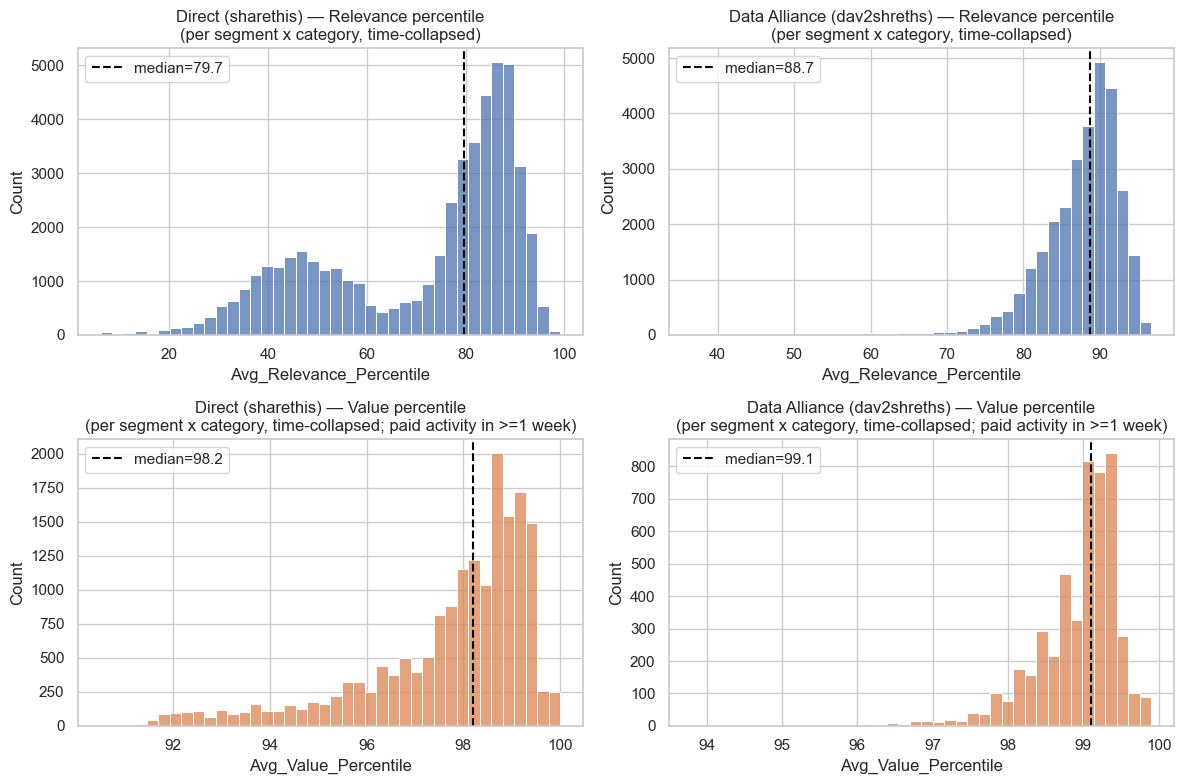

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, prov in enumerate(PROVIDERS):
    sc = seg_cat[prov]
    sns.histplot(sc['Avg_Relevance_Percentile'].dropna(), bins=40, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{PROVIDER_LABEL[prov]} — Relevance percentile\n(per segment x category, time-collapsed)")
    axes[0, i].axvline(sc['Avg_Relevance_Percentile'].median(), color="black", linestyle="--",
                        label=f"median={sc['Avg_Relevance_Percentile'].median():.1f}")
    axes[0, i].legend()

    sns.histplot(sc['Avg_Value_Percentile'].dropna(), bins=40, ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"{PROVIDER_LABEL[prov]} — Value percentile\n(per segment x category, time-collapsed; paid activity in >=1 week)")
    med = sc['Avg_Value_Percentile'].median()
    axes[1, i].axvline(med, color="black", linestyle="--", label=f"median={med:.1f}")
    axes[1, i].legend()
plt.tight_layout()
plt.show()


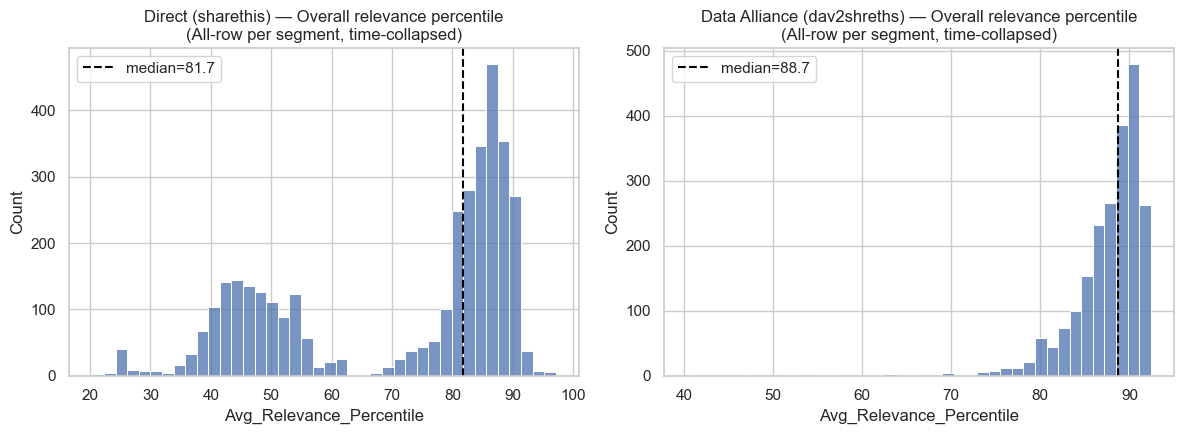

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, prov in enumerate(PROVIDERS):
    sa = seg_all[prov]
    sns.histplot(sa['Avg_Relevance_Percentile'].dropna(), bins=40, ax=axes[i], color="#4C72B0")
    axes[i].set_title(f"{PROVIDER_LABEL[prov]} — Overall relevance percentile\n(All-row per segment, time-collapsed)")
    axes[i].axvline(sa['Avg_Relevance_Percentile'].median(), color="black", linestyle="--",
                     label=f"median={sa['Avg_Relevance_Percentile'].median():.1f}")
    axes[i].legend()
plt.tight_layout()
plt.show()


In [8]:
summary_rows = []
for prov in PROVIDERS:
    sc, sa = seg_cat[prov], seg_all[prov]
    summary_rows.append({
        'provider': PROVIDER_LABEL[prov],
        'n_segments': sa['Full_Path'].nunique(),
        'percat_relevance_median': sc['Avg_Relevance_Percentile'].median(),
        'percat_value_median': sc['Avg_Value_Percentile'].median(),
        'percat_value_coverage': sc['Avg_Value_Percentile'].notna().mean(),
        'percat_median_week_to_week_std': sc['relevance_pctile_std_over_weeks'].median(),
        'overall_relevance_median': sa['Avg_Relevance_Percentile'].median(),
        'overall_value_median': sa['Avg_Value_Percentile'].median(),
        'overall_value_coverage': sa['Avg_Value_Percentile'].notna().mean(),
    })
pd.DataFrame(summary_rows).set_index('provider').round(2)


,n_segments,percat_relevance_median,percat_value_median,percat_value_coverage,percat_median_week_to_week_std,overall_relevance_median,overall_value_median,overall_value_coverage
provider,,,,,,,,
Direct (sharethis),3589,79.7,98.2,0.35,3.50,81.7,93.0,0.96
Data Alliance (dav2shreths),2146,88.7,99.1,0.16,2.03,88.7,96.0,0.89


## Section 2 — Category assignment: intrinsic taxonomy vs. performance best-fit

Two independent views of "what vertical does this segment belong to", both built on `seg_cat` (already
time-collapsed, category dimension kept, above):

- **Intrinsic** — derived from the segment's own path (`native_category` / `intrinsic_vertical`, already
  attached to `seg_cat`). For `dav2shreths`, TTD's Data Alliance already labels a native category in the
  path (e.g. `Data Alliance > Automotive > ...`). For `sharethis`, we use the topic node in the path
  (e.g. `Global > beauty & fitness > ...`), then map both providers' native labels onto the 14 TTD
  verticals with the `NATIVE_TO_VERTICAL` heuristic. ~60-88% of segments get a mapped intrinsic vertical;
  the rest (demographics, intent, seasonal, B2B, etc.) aren't topical and are left `Other/Unmapped`.
- **Performance best-fit** — the vertical where a segment's (time-collapsed) relevance percentile is most
  *unusually high relative to our own segment population in that vertical* — a within-category z-score,
  computed across the segment (space) dimension on top of the already time-collapsed values. We
  deliberately don't just take the raw highest percentile: category baselines differ a lot in this
  marketplace (e.g. Medical Health and News & Politics run structurally higher for nearly every segment
  we have, regardless of topic — see the diagnostic below), so a raw argmax would just pick those two
  verticals almost every time and tell us about the marketplace, not about the segment.

In [9]:
for prov in PROVIDERS:
    print(f"\n{PROVIDER_LABEL[prov]} — sample native_category -> intrinsic_vertical mapping:")
    print(seg_cat[prov][['Full_Path', 'native_category', 'intrinsic_vertical']].head(5).to_string(index=False))



Direct (sharethis) — sample native_category -> intrinsic_vertical mapping:
    Full_Path native_category intrinsic_vertical
Affordability   Affordability     Other/Unmapped
Affordability   Affordability     Other/Unmapped
Affordability   Affordability     Other/Unmapped
Affordability   Affordability     Other/Unmapped
Affordability   Affordability     Other/Unmapped

Data Alliance (dav2shreths) — sample native_category -> intrinsic_vertical mapping:
                                                             Full_Path      native_category     intrinsic_vertical
Data Alliance > Arts & Entertainment > Interest > Global > Attractions Arts & Entertainment Events and Attractions
Data Alliance > Arts & Entertainment > Interest > Global > Attractions Arts & Entertainment Events and Attractions
Data Alliance > Arts & Entertainment > Interest > Global > Attractions Arts & Entertainment Events and Attractions
Data Alliance > Arts & Entertainment > Interest > Global > Attractions Arts & Enterta

**Diagnostic: category baseline skew.** Median relevance percentile per vertical, computed across
*all* our segments (not per-segment) — if this varied only randomly we'd expect it flat; instead some
verticals are structurally higher for everyone, which is why best-fit uses a within-category z-score
rather than the raw percentile.

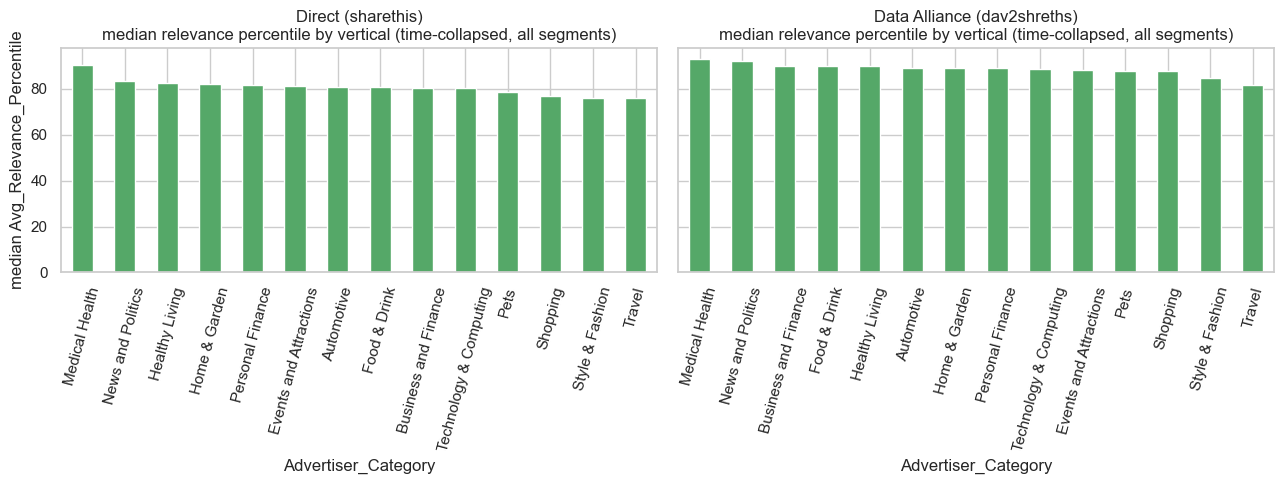

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, prov in zip(axes, PROVIDERS):
    baseline = (seg_cat[prov].groupby('Advertiser_Category')['Avg_Relevance_Percentile']
                .median().sort_values(ascending=False))
    baseline.plot(kind='bar', ax=ax, color="#55A868")
    ax.set_title(f"{PROVIDER_LABEL[prov]}\nmedian relevance percentile by vertical (time-collapsed, all segments)")
    ax.set_ylabel("median Avg_Relevance_Percentile")
    ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()


In [11]:
def compute_best_fit(sc):
    sc = sc.copy()
    sc['cat_mean'] = sc.groupby('Advertiser_Category')['Avg_Relevance_Percentile'].transform('mean')
    sc['cat_std'] = sc.groupby('Advertiser_Category')['Avg_Relevance_Percentile'].transform('std')
    sc['z'] = (sc['Avg_Relevance_Percentile'] - sc['cat_mean']) / sc['cat_std']
    idx = sc.groupby('Full_Path')['z'].idxmax()
    return sc.loc[idx, ['Full_Path', 'Advertiser_Category', 'Avg_Relevance_Percentile', 'z']].rename(
        columns={'Advertiser_Category': 'best_fit_vertical', 'Avg_Relevance_Percentile': 'best_fit_relevance_pctile', 'z': 'best_fit_z'})

best_fit = {}
for prov in PROVIDERS:
    bf = compute_best_fit(seg_cat[prov])
    intrinsic = seg_cat[prov][['Full_Path', 'intrinsic_vertical']].drop_duplicates('Full_Path')
    bf = bf.merge(intrinsic, on='Full_Path')
    bf['aligned'] = bf['best_fit_vertical'] == bf['intrinsic_vertical']
    best_fit[prov] = bf
    mapped = bf[bf.intrinsic_vertical != 'Other/Unmapped']
    print(f"{prov}: {len(bf)} segments | {len(mapped)} with mapped intrinsic vertical "
          f"({len(mapped)/len(bf):.0%}) | exact best-fit==intrinsic match rate: {mapped['aligned'].mean():.1%}")

best_fit['sharethis'].head()


sharethis: 3589 segments | 2151 with mapped intrinsic vertical (60%) | exact best-fit==intrinsic match rate: 9.1%
dav2shreths: 2146 segments | 1890 with mapped intrinsic vertical (88%) | exact best-fit==intrinsic match rate: 15.8%


,Full_Path,best_fit_vertical,best_fit_relevance_pctile,best_fit_z,intrinsic_vertical,aligned
0,Affordability,Medical Health,92.5,0.726726,Other/Unmapped,False
1,Asia > Arts & Entertainment,Business and Finance,39.5,-1.703207,Events and Attractions,False
2,Asia > Arts & Entertainment > Celebrities & Entertainment News,Travel,73.6,0.034383,Events and Attractions,False
3,Asia > Arts & Entertainment > Comics & Animation,Medical Health,55.5,-1.261200,Events and Attractions,False
4,Asia > Arts & Entertainment > Comics & Animation > Anime & Manga,Medical Health,54.0,-1.341791,Events and Attractions,False


In [12]:
### Diagnostic: does the argmax favor low-variance categories?
# The z-score best-fit is an argmax over 14 categories. A category with unusually low spread
# (std, across segments, of the already time-collapsed percentile) will mechanically win more
# often, even for segments with no real topical connection to it -- worth checking directly rather
# than assuming the mapping is clean.
for prov in PROVIDERS:
    spread = seg_cat[prov].groupby('Advertiser_Category')['Avg_Relevance_Percentile'].std().sort_values()
    win_share = best_fit[prov]['best_fit_vertical'].value_counts(normalize=True)
    diag = pd.DataFrame({'std_across_segments': spread, 'share_of_best_fit_wins': win_share}).sort_values('std_across_segments')
    print(f"\n=== {PROVIDER_LABEL[prov]}: category std vs. how often it wins best-fit ===")
    print(diag.round(3))



=== Direct (sharethis): category std vs. how often it wins best-fit ===
                        std_across_segments  share_of_best_fit_wins
Travel                                8.671                   0.203
Personal Finance                     17.559                   0.006
Style & Fashion                      18.266                   0.079
Medical Health                       18.612                   0.178
Business and Finance                 18.923                   0.315
Technology & Computing               19.231                   0.043
Automotive                           19.822                   0.020
Food & Drink                         19.874                   0.015
Shopping                             20.060                   0.038
Healthy Living                       20.414                   0.005
News and Politics                    21.276                   0.024
Events and Attractions               22.111                   0.048
Pets                                 22.276

Exact-match rates are low (best-fit rarely equals the heuristic intrinsic label one-for-one) — treat
the mapping as directional, not precise. It still tells a real story: segments frequently out-perform in a
vertical *other than* their home topic, which is genuinely useful for sales targeting (see Section 7).

## Section 3 — Vertical leaderboard

Where do we perform best and worst, by advertiser vertical, using segments' best-fit relevance percentile?

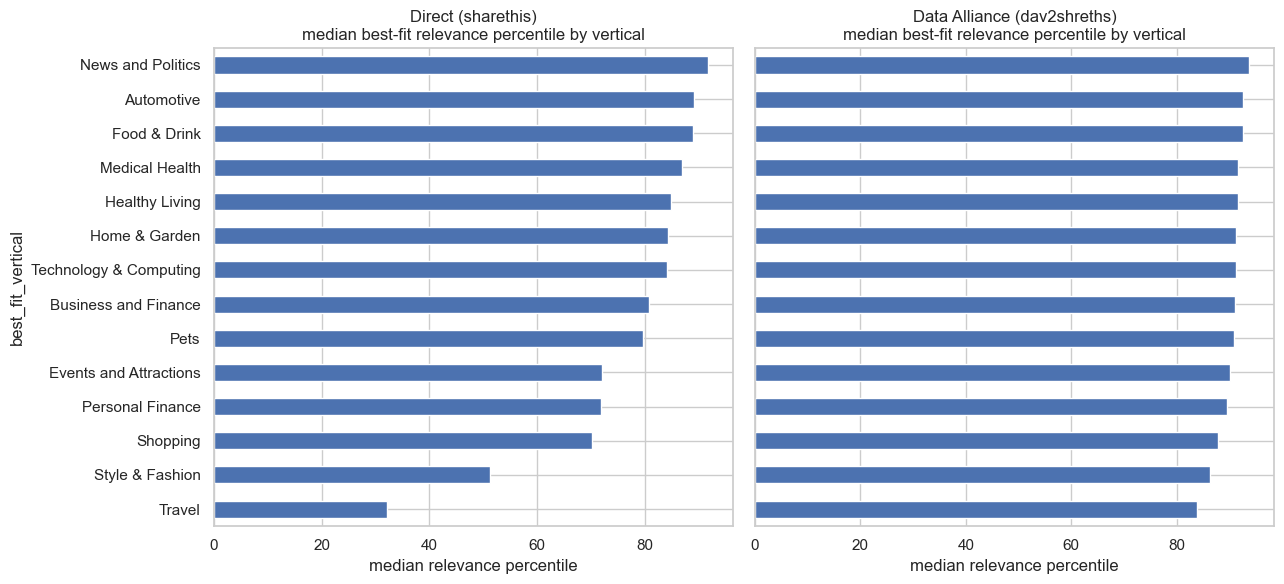

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, prov in zip(axes, PROVIDERS):
    lb = (best_fit[prov].groupby('best_fit_vertical')['best_fit_relevance_pctile']
          .agg(['median', 'mean', 'count']).sort_values('median', ascending=False))
    lb['median'].plot(kind='barh', ax=ax, color="#4C72B0")
    ax.set_title(f"{PROVIDER_LABEL[prov]}\nmedian best-fit relevance percentile by vertical")
    ax.set_xlabel("median relevance percentile")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()


## Section 4 — Trends over time

The complement to Section 1: here we collapse *space*, keep time, and look at three series across the
27 weeks, all from **`all_raw`** (the `Advertiser_Category == 'All'` rows, time kept — the well-populated
source, unlike the sparse per-category rows):

- **Relevance percentile** — how well segments match converters, marketplace-relative.
- **Value percentile** — relevance per penny of cost, marketplace-relative. Value ≈ Relevance / Price, so
  if price has actually been cut, Value should rise even with relevance flat.
- **`Data_Cost`** — the closest thing in this file to "price." If Value hasn't moved the way price would
  predict, this is the first place to look.

`processed` (category rows) is used only for the earlier category-level relevance trend that was already
here; it's not a good source for Value or Cost trends given ~12% coverage per row.

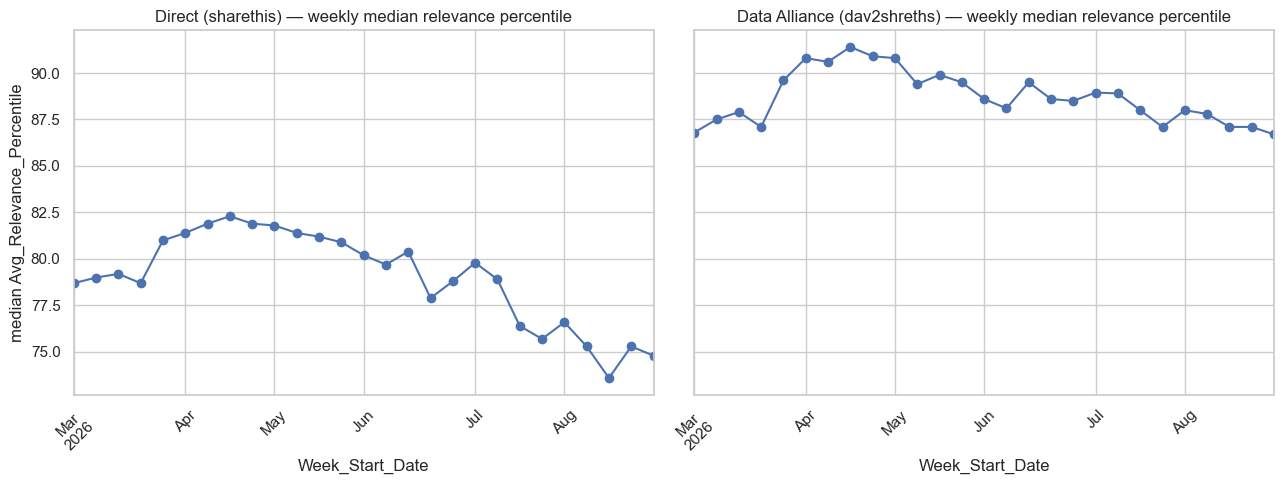

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, prov in zip(axes, PROVIDERS):
    sub = processed[prov]
    weekly = sub.groupby('Week_Start_Date')['Avg_Relevance_Percentile'].median()
    weekly.plot(ax=ax, marker='o', color="#4C72B0")
    ax.set_title(f"{PROVIDER_LABEL[prov]} — weekly median relevance percentile")
    ax.set_ylabel("median Avg_Relevance_Percentile")
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


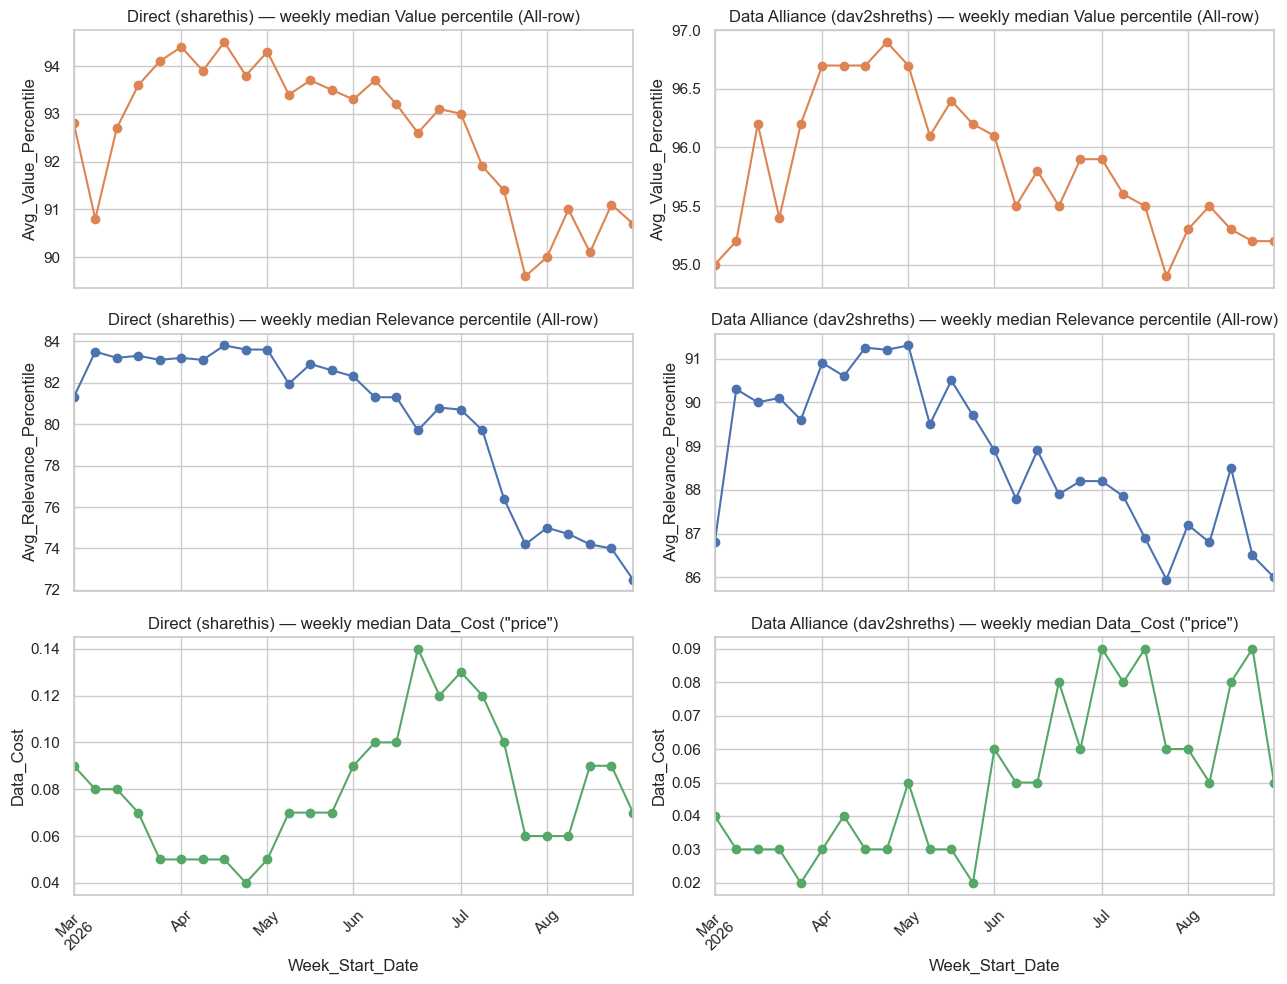

In [15]:
weekly_all = {}
for prov in PROVIDERS:
    w = all_raw[prov].groupby('Week_Start_Date').agg(
        median_value_pctile=('Avg_Value_Percentile', 'median'),
        median_relevance_pctile=('Avg_Relevance_Percentile', 'median'),
        median_data_cost=('Data_Cost', 'median'),
        n_value_obs=('Avg_Value_Percentile', 'count'),
    ).reset_index().sort_values('Week_Start_Date')
    w['week_idx'] = np.arange(len(w))
    weekly_all[prov] = w

fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex='col')
for i, prov in enumerate(PROVIDERS):
    w = weekly_all[prov]
    w.plot(x='Week_Start_Date', y='median_value_pctile', ax=axes[0, i], marker='o', color="#DD8452", legend=False)
    axes[0, i].set_title(f"{PROVIDER_LABEL[prov]} — weekly median Value percentile (All-row)")
    axes[0, i].set_ylabel("Avg_Value_Percentile")

    w.plot(x='Week_Start_Date', y='median_relevance_pctile', ax=axes[1, i], marker='o', color="#4C72B0", legend=False)
    axes[1, i].set_title(f"{PROVIDER_LABEL[prov]} — weekly median Relevance percentile (All-row)")
    axes[1, i].set_ylabel("Avg_Relevance_Percentile")

    w.plot(x='Week_Start_Date', y='median_data_cost', ax=axes[2, i], marker='o', color="#55A868", legend=False)
    axes[2, i].set_title(f"{PROVIDER_LABEL[prov]} — weekly median Data_Cost (\"price\")")
    axes[2, i].set_ylabel("Data_Cost")
    axes[2, i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


In [16]:
### Is there actually a trend? Linear regression of each weekly series against week index.
for prov in PROVIDERS:
    w = weekly_all[prov]
    print(f"\n=== {prov}: trend over {len(w)} weeks ===")
    for col in ['median_value_pctile', 'median_relevance_pctile', 'median_data_cost']:
        sub = w.dropna(subset=[col])
        slope, intercept, r, p, se = stats.linregress(sub['week_idx'], sub[col])
        direction = "UP" if slope > 0 else "DOWN"
        sig = "significant" if p < 0.05 else "not significant"
        print(f"  {col:26s} slope/week={slope:+.4f} ({direction}, {sig}, p={p:.4f}, r={r:+.2f})  "
              f"first={sub[col].iloc[0]:.2f} -> last={sub[col].iloc[-1]:.2f}")



=== sharethis: trend over 27 weeks ===
  median_value_pctile        slope/week=-0.1213 (DOWN, significant, p=0.0002, r=-0.65)  first=92.80 -> last=90.70
  median_relevance_pctile    slope/week=-0.4071 (DOWN, significant, p=0.0000, r=-0.87)  first=81.30 -> last=72.50
  median_data_cost           slope/week=+0.0011 (UP, not significant, p=0.0902, r=+0.33)  first=0.09 -> last=0.07

=== dav2shreths: trend over 27 weeks ===
  median_value_pctile        slope/week=-0.0340 (DOWN, significant, p=0.0164, r=-0.46)  first=95.00 -> last=95.20
  median_relevance_pctile    slope/week=-0.1528 (DOWN, significant, p=0.0000, r=-0.71)  first=86.80 -> last=86.00
  median_data_cost           slope/week=+0.0021 (UP, significant, p=0.0000, r=+0.74)  first=0.04 -> last=0.05


## Section 5 — Dstillery benchmark comparison

Dstillery's published claim, for in-category campaigns: **median relevance in the 98th percentile,
median value in the 99.5th percentile**, across a marketplace of 1M+ segments. Three comparison points,
from most to least cherry-picked:

- **Best-fit vertical** — each segment scored in whichever of the 14 verticals it happens to rank highest
  in (Section 2's z-score argmax). This is a selection effect — picking the best of 14 draws per segment
  — so it's an *upper bound*, not a fair "in-category" read.
- **Native in-category** — each segment scored in **its own intrinsic/home vertical** (the
  `NATIVE_TO_VERTICAL`-mapped taxonomy category, no cherry-picking across the other 13). This is the
  closest match to what Dstillery's claim actually describes: how a segment performs when used in its
  own category, not its best category. Only covers the ~60-88% of segments with a mapped intrinsic
  vertical.
- **Overall (`All`-row)** — each segment's TTD-computed cross-category aggregate, not tied to any single
  vertical. Far better data coverage; included as a sanity check.

None of these are a row-for-row comparison (we have no Dstillery segment data) — all three are our
numbers next to their published number.

In [17]:
comparison_rows = []
for prov in PROVIDERS:
    bf, sc, sa = best_fit[prov], seg_cat[prov], seg_all[prov]

    bf_with_value = bf.merge(sc[['Full_Path', 'Advertiser_Category', 'Avg_Value_Percentile']],
                              left_on=['Full_Path', 'best_fit_vertical'],
                              right_on=['Full_Path', 'Advertiser_Category'], how='left')

    # native in-category: score each segment in its OWN intrinsic vertical, no cherry-picking across the other 13
    native = sc[sc['Advertiser_Category'] == sc['intrinsic_vertical']]

    comparison_rows.append({
        'provider': PROVIDER_LABEL[prov],
        'bestfit_median_relevance_pctile': bf['best_fit_relevance_pctile'].median(),
        'bestfit_median_value_pctile': bf_with_value['Avg_Value_Percentile'].median(),
        'native_median_relevance_pctile': native['Avg_Relevance_Percentile'].median(),
        'native_median_value_pctile': native['Avg_Value_Percentile'].median(),
        'native_n_segments': len(native),
        'native_value_coverage': native['Avg_Value_Percentile'].notna().mean(),
        'overall_median_relevance_pctile': sa['Avg_Relevance_Percentile'].median(),
        'overall_median_value_pctile': sa['Avg_Value_Percentile'].median(),
        'dstillery_median_relevance_pctile': DSTILLERY_BENCHMARK['median_relevance_percentile'],
        'dstillery_median_value_pctile': DSTILLERY_BENCHMARK['median_value_percentile'],
    })
comparison_df = pd.DataFrame(comparison_rows).set_index('provider').round(2)
comparison_df


,bestfit_median_relevance_pctile,bestfit_median_value_pctile,native_median_relevance_pctile,native_median_value_pctile,native_n_segments,native_value_coverage,overall_median_relevance_pctile,overall_median_value_pctile,dstillery_median_relevance_pctile,dstillery_median_value_pctile
provider,,,,,,,,,,
Direct (sharethis),84.4,98.7,81.0,98.25,2151,0.66,81.7,93.0,98.0,99.5
Data Alliance (dav2shreths),90.2,99.1,88.7,98.80,1890,0.42,88.7,96.0,98.0,99.5


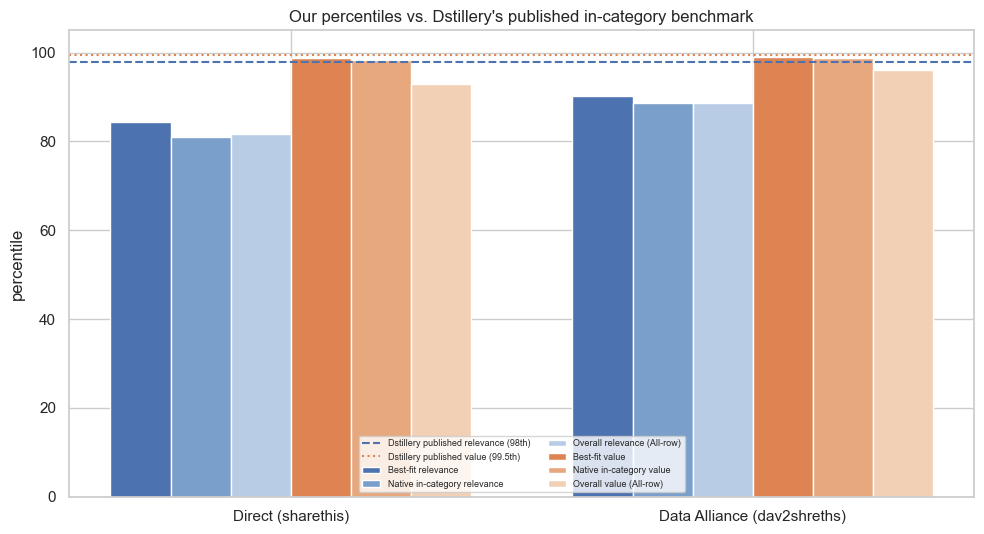

In [18]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(PROVIDERS))
width = 0.13
metrics = [
    ('bestfit_median_relevance_pctile', 'Best-fit relevance', "#4C72B0"),
    ('native_median_relevance_pctile', 'Native in-category relevance', "#7A9FCB"),
    ('overall_median_relevance_pctile', 'Overall relevance (All-row)', "#B8CCE6"),
    ('bestfit_median_value_pctile', 'Best-fit value', "#DD8452"),
    ('native_median_value_pctile', 'Native in-category value', "#E7A87E"),
    ('overall_median_value_pctile', 'Overall value (All-row)', "#F2D0B6"),
]
for j, (col, label, color) in enumerate(metrics):
    vals = [comparison_df.loc[PROVIDER_LABEL[p], col] for p in PROVIDERS]
    ax.bar(x + (j - 2.5) * width, vals, width, label=label, color=color)
ax.axhline(DSTILLERY_BENCHMARK['median_relevance_percentile'], color="#4C72B0", linestyle="--",
           label="Dstillery published relevance (98th)")
ax.axhline(DSTILLERY_BENCHMARK['median_value_percentile'], color="#DD8452", linestyle=":",
           label="Dstillery published value (99.5th)")
ax.set_xticks(x)
ax.set_xticklabels([PROVIDER_LABEL[p] for p in PROVIDERS])
ax.set_ylabel("percentile")
ax.set_ylim(0, 105)
ax.legend(fontsize=6.5, loc='lower center', ncol=2)
ax.set_title("Our percentiles vs. Dstillery's published in-category benchmark")
plt.tight_layout()
plt.show()


---
## SALES-READY SUMMARY — safe to share externally

Curated for client-facing use. Vertical names and headline percentile stats only — no underperformer
detail, no internal channel comparisons.

In [19]:
print("Headline: our native in-category performance vs. Dstillery's published in-category benchmark")
print("(native in-category = segment scored in its own home vertical, no cherry-picking -- the fair comparison)\n")
print(comparison_df[['native_median_relevance_pctile', 'dstillery_median_relevance_pctile',
                      'native_median_value_pctile', 'dstillery_median_value_pctile',
                      'native_n_segments', 'native_value_coverage']])
print("\nFor reference, best-fit (each segment's single best-scoring vertical, an upper bound) and the")
print("overall All-row aggregate are also available in `comparison_df` -- see Section 5.")


Headline: our native in-category performance vs. Dstillery's published in-category benchmark
(native in-category = segment scored in its own home vertical, no cherry-picking -- the fair comparison)

                             native_median_relevance_pctile  dstillery_median_relevance_pctile  native_median_value_pctile  \
provider                                                                                                                     
Direct (sharethis)                                     81.0                               98.0                       98.25   
Data Alliance (dav2shreths)                            88.7                               98.0                       98.80   

                             dstillery_median_value_pctile  native_n_segments  native_value_coverage  
provider                                                                                              
Direct (sharethis)                                    99.5               2151             

In [20]:
TOP_N_VERTICALS = 5
MIN_SEGMENTS_PER_VERTICAL = 10

for prov in PROVIDERS:
    vol = seg_all[prov].set_index('Full_Path')['Effective_Impression_Count_max']
    qualifying_segments = vol[vol >= VOLUME_THRESHOLD].index
    bf = best_fit[prov][best_fit[prov].Full_Path.isin(qualifying_segments)]

    lb = (bf.groupby('best_fit_vertical')['best_fit_relevance_pctile']
          .agg(['median', 'count']).query('count >= @MIN_SEGMENTS_PER_VERTICAL')
          .sort_values('median', ascending=False).head(TOP_N_VERTICALS))
    print(f"\n=== {PROVIDER_LABEL[prov]}: top {TOP_N_VERTICALS} verticals by median relevance percentile "
          f"(volume-filtered via All-row Effective_Impression_Count, >= {MIN_SEGMENTS_PER_VERTICAL} qualifying segments) ===")
    print(lb.round(1))



=== Direct (sharethis): top 5 verticals by median relevance percentile (volume-filtered via All-row Effective_Impression_Count, >= 10 qualifying segments) ===
                      median  count
best_fit_vertical                  
Automotive              92.0     34
Medical Health          89.6    474
Business and Finance    88.5    823
Food & Drink            86.2     36
Personal Finance        85.2     12

=== Data Alliance (dav2shreths): top 5 verticals by median relevance percentile (volume-filtered via All-row Effective_Impression_Count, >= 10 qualifying segments) ===
                   median  count
best_fit_vertical               
News and Politics    93.9     17
Automotive           92.6     78
Food & Drink         92.1     12
Medical Health       91.4    374
Home & Garden        91.0     57


In [21]:
TOP_N_SEGMENTS = 10

for prov in PROVIDERS:
    vol = seg_all[prov].set_index('Full_Path')['Effective_Impression_Count_max']
    qualifying_segments = vol[vol >= VOLUME_THRESHOLD].index
    bf = best_fit[prov][best_fit[prov].Full_Path.isin(qualifying_segments)].sort_values(
        'best_fit_relevance_pctile', ascending=False).head(TOP_N_SEGMENTS)
    print(f"\n=== {PROVIDER_LABEL[prov]}: top {TOP_N_SEGMENTS} segments (volume-filtered) ===")
    print(bf[['Full_Path', 'best_fit_vertical', 'best_fit_relevance_pctile']].to_string(index=False))



=== Direct (sharethis): top 10 segments (volume-filtered) ===
                                                                    Full_Path    best_fit_vertical  best_fit_relevance_pctile
         Asia > Business & Industrial > Business Finance > Investment Banking               Travel                       98.5
     Interest from Social Activity > Seasonal > Summer > Outdoor Entertainers               Travel                       96.7
                      Interest from Social Activity > Seasonal > Summer > Fun               Travel                       95.7
Global > business & industrial > retail trade > retail equipment & technology               Travel                       95.4
                     Global > shopping > toys > outdoor toys & play equipment               Travel                       95.2
                                        Political > Politician > Ron DeSantis    News and Politics                       95.2
                                       US > Validated D

---
## INTERNAL ONLY — do not share externally

Full distributions, laggards, channel comparison, and methodology caveats for our own use.

In [22]:
for prov in PROVIDERS:
    vol = seg_all[prov].set_index('Full_Path')['Effective_Impression_Count_max']
    qualifying_segments = vol[vol >= VOLUME_THRESHOLD].index
    bf = best_fit[prov][best_fit[prov].Full_Path.isin(qualifying_segments)].sort_values(
        'best_fit_relevance_pctile', ascending=True).head(TOP_N_SEGMENTS)
    print(f"\n=== {PROVIDER_LABEL[prov]}: bottom {TOP_N_SEGMENTS} segments by best-fit relevance percentile "
          f"(volume-filtered, internal use only) ===")
    print(bf[['Full_Path', 'best_fit_vertical', 'best_fit_relevance_pctile']].to_string(index=False))



=== Direct (sharethis): bottom 10 segments by best-fit relevance percentile (volume-filtered, internal use only) ===
                                                                        Full_Path best_fit_vertical  best_fit_relevance_pctile
Asia > Autos & Vehicles > Vehicle Shopping > Vehicle Specs, Reviews & Comparisons              Pets                      28.20
                                    Intent > Shopping > Consumer Electronics > PC              Pets                      28.60
                                        Intent > Auto Buyers > Car Make > Renault              Pets                      29.15
              Asia > Arts & Entertainment > Movies > Bollywood & South Asian Film              Pets                      31.20
            Asia > Online Communities > Dating & Personals > Matrimonial Services              Pets                      31.20
                 Asia > Computers & Electronics > Software > Educational Software              Pets                     

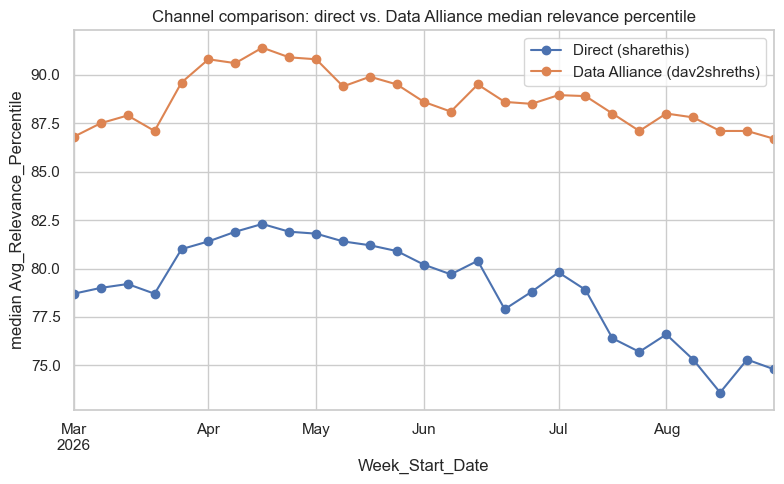

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
for prov, color in zip(PROVIDERS, ["#4C72B0", "#DD8452"]):
    sub = processed[prov]
    weekly = sub.groupby('Week_Start_Date')['Avg_Relevance_Percentile'].median()
    weekly.plot(ax=ax, marker='o', label=PROVIDER_LABEL[prov], color=color)
ax.set_title("Channel comparison: direct vs. Data Alliance median relevance percentile")
ax.set_ylabel("median Avg_Relevance_Percentile")
ax.legend()
plt.tight_layout()
plt.show()


### Segment stability over time

`relevance_pctile_std_over_weeks` (built into `seg_cat`) makes the time dimension visible again instead
of just collapsing it away — a segment can have an impressive median best-fit percentile built on 27
noisy, swinging weeks, which is a weaker claim than the same median built on 27 consistent ones.

In [24]:
for prov in PROVIDERS:
    vol = seg_all[prov].set_index('Full_Path')['Effective_Impression_Count_max']
    qualifying = vol[vol >= VOLUME_THRESHOLD].index
    bf = best_fit[prov][best_fit[prov].Full_Path.isin(qualifying)].merge(
        seg_cat[prov][['Full_Path', 'Advertiser_Category', 'relevance_pctile_std_over_weeks', 'n_weeks_observed']],
        left_on=['Full_Path', 'best_fit_vertical'], right_on=['Full_Path', 'Advertiser_Category'], how='left')
    print(f"\n=== {PROVIDER_LABEL[prov]}: week-to-week std of relevance percentile, volume-filtered segments ===")
    print(bf['relevance_pctile_std_over_weeks'].describe().round(1))
    unstable = bf.sort_values('relevance_pctile_std_over_weeks', ascending=False).head(5)
    print("\nmost volatile (high std) high-volume segments -- verify before quoting a single number for these:")
    print(unstable[['Full_Path', 'best_fit_vertical', 'best_fit_relevance_pctile', 'relevance_pctile_std_over_weeks']].to_string(index=False))



=== Direct (sharethis): week-to-week std of relevance percentile, volume-filtered segments ===
count    2440.0
mean        4.6
std         2.7
min         1.0
25%         2.6
50%         3.6
75%         5.9
max        18.3
Name: relevance_pctile_std_over_weeks, dtype: float64

most volatile (high std) high-volume segments -- verify before quoting a single number for these:
                                    Full_Path      best_fit_vertical  best_fit_relevance_pctile  relevance_pctile_std_over_weeks
         Political > Politician > Val Demings               Shopping                       50.9                        18.331813
       Asia > Intent > Auto Buyers > Car Make Technology & Computing                       70.3                        17.506974
       Intent > Auto Buyers > Car Make > Opel                   Pets                       44.4                        17.312172
       Asia > Intent > Services > Photography Technology & Computing                       72.4            


most volatile (high std) high-volume segments -- verify before quoting a single number for these:
                                                                                   Full_Path best_fit_vertical  best_fit_relevance_pctile  relevance_pctile_std_over_weeks
                     Data Alliance > Books & Literature > Interest > Global > Magazine Genre    Medical Health                       83.5                         8.656514
                      Data Alliance > Technology & Computing > Interest > Global > Computers    Medical Health                       85.8                         8.344290
Data Alliance > Demographic > Interest > Global > Education & Occupation > Employment Status    Medical Health                       79.6                         8.322528
                           Data Alliance > Retail > Interest > Global > Consumer Electronics    Medical Health                       88.1                         8.244155
                           Data Alliance > Bus

### Caveats & limitations

- **Volume filtering was fixed to use the `All`-row `Effective_Impression_Count`** (≈70% field coverage),
  not the per-category field (≈12% coverage). Earlier drafts of this notebook built the filter off the
  sparser category-level field, which understated qualifying segments by treating missing per-category
  delivery data as if it were low volume.
- **`NATIVE_TO_VERTICAL` mapping is a heuristic**, built by inspecting path taxonomy labels, not a
  vetted crosswalk. Exact match rate against performance best-fit is low (~9-16%) — treat "intrinsic
  vertical" as directional context, not ground truth. Worth a pass with someone who owns the taxonomy.
- **Category baselines differ sharply in this marketplace** (Medical Health and News & Politics run
  structurally higher for nearly every segment we have) — this is corrected for via within-category
  z-scoring in the best-fit calculation, but it also means "raw percentile in vertical X" isn't
  comparable to "raw percentile in vertical Y" without that correction.
- **The best-fit argmax can be pulled toward low-variance categories** (see the diagnostic in Section 2):
  a vertical where our segments' percentiles barely spread out will produce large z-scores from small
  differences and win more often, independent of real topical fit. That's visible in practice — e.g.
  several sharethis segments with no travel connection (investment banking, retail equipment, toys) land
  in "Travel" as their best-fit vertical, and several weak segments land in "Pets" simply because it's
  their *least bad* option. Spot-check any single-segment best-fit claim against the diagnostic table
  before using it in a specific pitch.
- **"Best-fit vertical" is an upper bound for the Dstillery comparison, not a fair "in-category" read** —
  it's each segment's single best-scoring vertical out of 14, a selection effect. "Native in-category"
  (scoring each segment in its own mapped home vertical, no cherry-picking) is the closer match to what
  Dstillery's claim describes, and is the number led with in the sales-ready headline — but it only covers
  segments with a mapped intrinsic vertical (~60-88%), and its value-percentile figure has lower coverage
  still (~42-66%) since it's restricted to one specific category per segment rather than the best-covered
  one.
- **Value percentile coverage is sparse per category** (~11-13% of category rows have paid activity to
  compute it), so value-based rankings by vertical are noisier than relevance-based ones — call out
  actual segment counts, not just percentiles, whenever quoting a value stat. The `All`-row overall value
  percentile has much better coverage and is a useful sanity check (Section 5).
- **Dstillery comparison is a published-benchmark comparison, not a head-to-head** — we don't have their
  segment-level scores, only their blog's headline claim.
- `VOLUME_THRESHOLD` (`All`-row `Effective_Impression_Count` >= 1000 in any week) — revisit if leaderboards
  look thin for a given vertical.
- **Time-collapsing uses the median across 27 weeks**, chosen for robustness to a single noisy week —
  `relevance_pctile_std_over_weeks` (in `seg_cat`) exposes how much that median is actually hiding, and is
  worth checking before quoting any single segment's number in a specific pitch (see the stability
  diagnostic above).
